In [28]:
import os
from dotenv import load_dotenv

load_dotenv(dotenv_path="/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/notebooks/.env", override=True)

key = os.getenv("SUPABASE_SERVICE_KEY")
print("First 20 chars:", key[:20] if key else "None")
print("Last 10 chars:", key[-10:] if key else "None")
print("Length:", len(key) if key else 0)

First 20 chars: eyJhbGciOiJIUzI1NiIs
Last 10 chars: 3IjoUh_IVM
Length: 219


In [29]:
from dotenv import load_dotenv
from supabase import create_client, Client
import pandas as pd
import numpy as np
import os

load_dotenv(dotenv_path="/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/notebooks/.env")

supabase: Client = create_client(
    os.getenv("SUPABASE_URL"),
    os.getenv("SUPABASE_SERVICE_KEY")
)

txn_res = supabase.table("user_transactions").select("*").execute()
fin_res = supabase.table("user_finances").select("*").execute()

print("Transactions:", len(txn_res.data))
print("Finances:", len(fin_res.data))

Transactions: 52
Finances: 10


In [30]:
# Debug cell — run this before anything else
print("=== user_transactions ===")
print(f"Rows: {len(txn_res.data)}")
print(f"Data: {txn_res.data[:3]}")  # first 3 rows

print("\n=== user_finances ===")
print(f"Rows: {len(fin_res.data)}")
print(f"Data: {fin_res.data[:3]}")

print("\n=== df_txn columns ===")
print(df_txn.columns.tolist())
print(df_txn.shape)

=== user_transactions ===
Rows: 52
Data: [{'id': 'a2e95c63-d803-48f3-a347-dec1dcdae5ff', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 32.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:33:41.272+00:00'}, {'id': '7bdb8fad-87e4-4fe3-8be2-33118837b438', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 32.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:33:42.905+00:00'}, {'id': 'dc6e0f9f-8879-4036-8063-8aec8ebcb9ff', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 322333.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:51:26.204+00:00'}]

=== user_finances ===
Rows: 10
Data: [{'id': '94c79464-6f31-4d0b-8d28-6d4415d47c6e', 'user_id': '8083dde7-b9c4-47a8-ab80-403db23bbfa3', 'balance': 5000.0, 'to

# Debug cell — run this before anything else
print("=== user_transactions ===")
print(f"Rows: {len(txn_res.data)}")
print(f"Data: {txn_res.data[:3]}")  # first 3 rows

print("\n=== user_finances ===")
print(f"Rows: {len(fin_res.data)}")
print(f"Data: {fin_res.data[:3]}")

print("\n=== df_txn columns ===")
print(df_txn.columns.tolist())
print(df_txn.shape)# Load & clean

In [32]:
df_txn = pd.DataFrame(txn_res.data)
df_fin = pd.DataFrame(fin_res.data)

df_txn["created_at"] = pd.to_datetime(df_txn["created_at"], utc=True)
df_txn["amount"] = df_txn["amount"].astype(float)
df_txn["month"] = df_txn["created_at"].dt.to_period("M")

print("Transactions:", len(df_txn), "rows |", df_txn["user_id"].nunique(), "users")
print("\nTypes:\n", df_txn["type"].value_counts().to_string())
print("\nCategories:\n", df_txn["category"].value_counts().to_string())
print("\nDate range:", df_txn["created_at"].min().date(), "to", df_txn["created_at"].max().date())

Transactions: 52 rows | 8 users

Types:
 type
expense    31
deposit    21

Categories:
 category
Income           21
Subscriptions    16
Shopping          5
Bills             3
Dining            2
Transport         2
Other             2
Groceries         1

Date range: 2026-02-15 to 2026-03-04


/var/folders/_l/vdgqbw4x0q99dgnnpmyn9v3m0000gn/T/ipykernel_2557/1010023783.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_txn["month"] = df_txn["created_at"].dt.to_period("M")


# Quick EDA plots

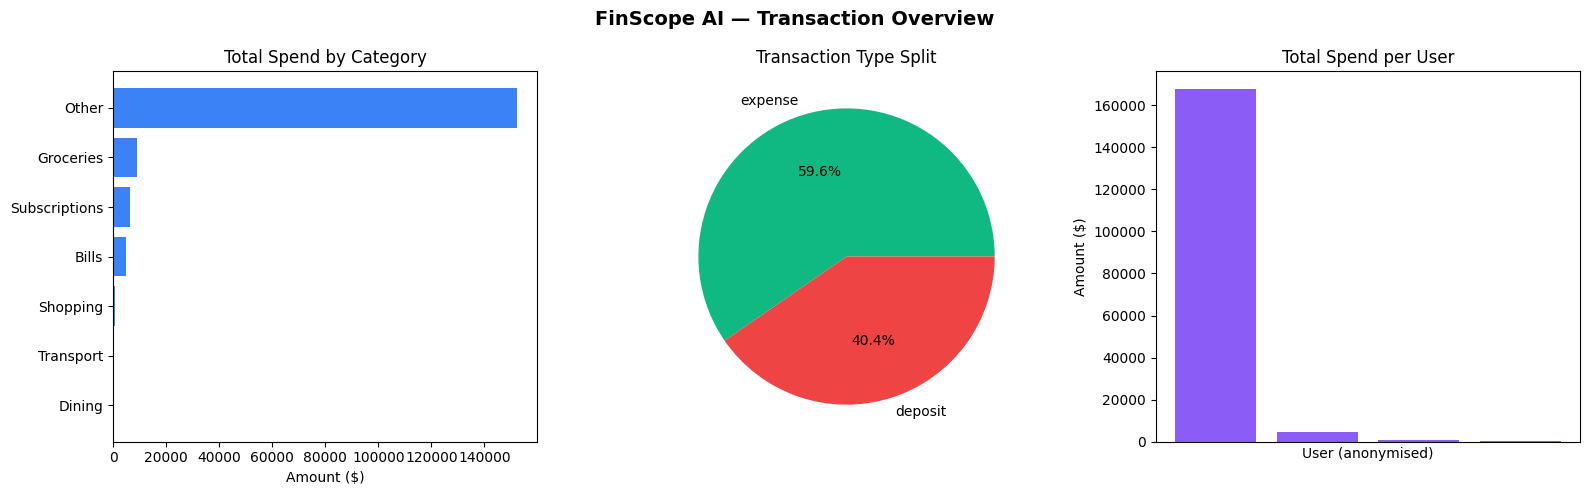

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("FinScope AI — Transaction Overview", fontsize=14, fontweight="bold")

# Plot 1: spend by category
expenses = df_txn[df_txn["type"] == "expense"]
cat_totals = expenses.groupby("category")["amount"].sum().sort_values(ascending=True)
axes[0].barh(cat_totals.index, cat_totals.values, color="#3b82f6")
axes[0].set_title("Total Spend by Category")
axes[0].set_xlabel("Amount ($)")

# Plot 2: transaction type split
type_counts = df_txn["type"].value_counts()
axes[1].pie(type_counts.values, labels=type_counts.index,
            autopct="%1.1f%%", colors=["#10b981", "#ef4444", "#f59e0b"])
axes[1].set_title("Transaction Type Split")

# Plot 3: spend per user
user_spend = expenses.groupby("user_id")["amount"].sum().sort_values(ascending=False)
axes[2].bar(range(len(user_spend)), user_spend.values, color="#8b5cf6")
axes[2].set_title("Total Spend per User")
axes[2].set_xlabel("User (anonymised)")
axes[2].set_ylabel("Amount ($)")
axes[2].set_xticks([])

plt.tight_layout()
plt.show()

# Build user feature matrix for clustering

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Category spend per user (expenses only)
cat_pivot = expenses.groupby(["user_id", "category"])["amount"]\
                    .sum().unstack(fill_value=0)

# Join finance summary
fin_indexed = df_fin.set_index("user_id")[["balance", "total_income", "total_expenses"]]
user_features = cat_pivot.join(fin_indexed, how="left").fillna(0)

# Derived features
user_features["savings_rate"] = (
    (user_features["total_income"] - user_features["total_expenses"])
    / user_features["total_income"].replace(0, np.nan)
).fillna(0).clip(0, 1)

user_features["txn_count"]    = expenses.groupby("user_id").size().reindex(user_features.index, fill_value=0)
user_features["avg_txn_size"] = expenses.groupby("user_id")["amount"].mean().reindex(user_features.index, fill_value=0)

print(f" Feature matrix: {user_features.shape[0]} users × {user_features.shape[1]} features")
print(user_features.round(2))

 Feature matrix: 4 users × 13 features
                                       Bills  Dining  Groceries     Other  \
user_id                                                                     
81a994e9-72e9-4de1-a954-01dbac7e37f3  4821.0   100.0     8900.0  152332.0   
a9c0974d-dc7e-42ce-b9b5-28159c62f649     0.0     0.0        0.0       0.0   
bbbba7eb-c6cd-40ac-9068-acd0bc34df5b     0.0     0.0        0.0       0.0   
e7614297-8f8a-43a4-bbfe-ea8b4c107c7d   100.0   100.0        0.0       0.0   

                                      Shopping  Subscriptions  Transport  \
user_id                                                                    
81a994e9-72e9-4de1-a954-01dbac7e37f3    721.00         632.00      200.0   
a9c0974d-dc7e-42ce-b9b5-28159c62f649      0.00         400.00        0.0   
bbbba7eb-c6cd-40ac-9068-acd0bc34df5b      0.00        4696.00        0.0   
e7614297-8f8a-43a4-bbfe-ea8b4c107c7d      0.01         554.97      200.0   

                                         

# Elbow method + cluster

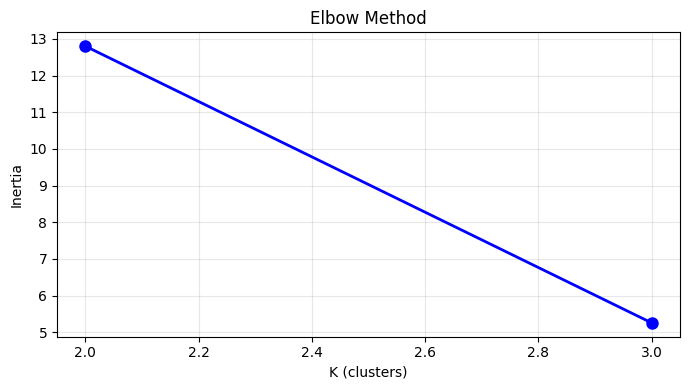

In [36]:
X = StandardScaler().fit_transform(user_features)

inertias = []
K_range = range(2, min(8, len(user_features)))
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    inertias.append(km.fit(X).inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(K_range), inertias, "bo-", linewidth=2, markersize=8)
plt.xlabel("K (clusters)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# The elbow only goes to K=3 because you only have 10 users — with small data the elbow method is limited. Use K=3, it's the right call. The curve still drops meaningfully from 2 to 3

In [37]:
K = 3
km = KMeans(n_clusters=K, random_state=42, n_init=10)
user_features["cluster"] = km.fit_predict(X)

print("Users per cluster:")
print(user_features["cluster"].value_counts().sort_index().to_string())

Users per cluster:
cluster
0    2
1    1
2    1


## PCA Scatter Plot

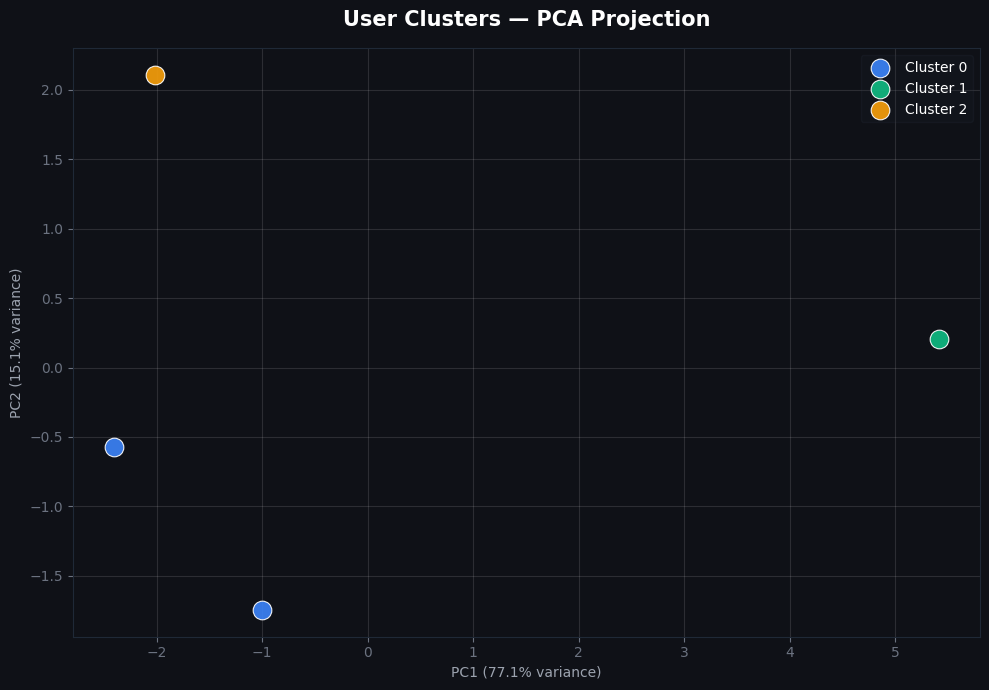

In [38]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

COLORS = ["#3b82f6", "#10b981", "#f59e0b"]
BG = "#0f1117"

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

for cid in range(K):
    mask = user_features["cluster"].values == cid
    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        label=f"Cluster {cid}",
        color=COLORS[cid], s=180,
        edgecolors="white", linewidths=0.8, alpha=0.92, zorder=3
    )

ax.set_title("User Clusters — PCA Projection", fontsize=15, fontweight="bold", color="white", pad=16)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)", color="#9ca3af")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)", color="#9ca3af")
ax.tick_params(colors="#6b7280")
ax.spines[:].set_color("#1f2937")
ax.grid(alpha=0.12, color="white")
legend = ax.legend(framealpha=0.15, labelcolor="white", facecolor="#1f2937", edgecolor="#374151")
plt.tight_layout()
plt.show()



# Cluster Profile Heatmap

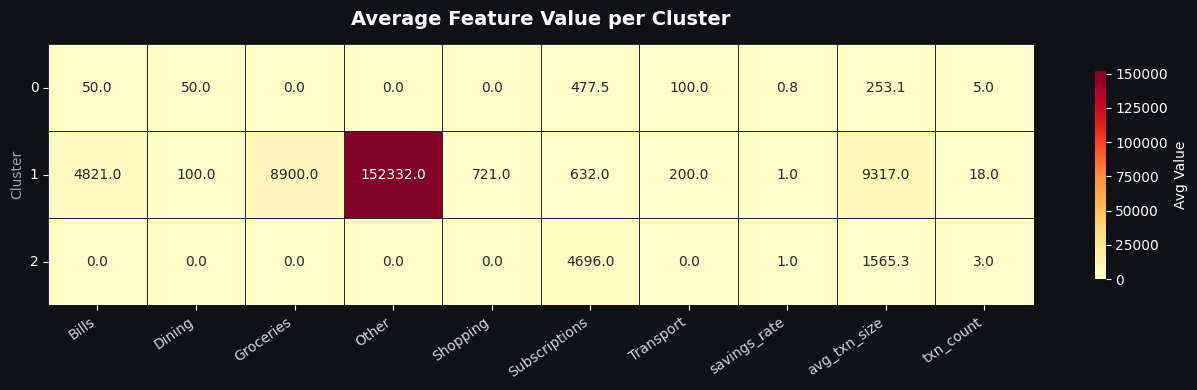


Cluster profiles:
          Bills  Dining  Groceries     Other  Shopping  Subscriptions  Transport  savings_rate  avg_txn_size  txn_count
cluster                                                                                                                
0          50.0    50.0        0.0       0.0       0.0         477.48      100.0          0.79        253.05        5.0
1        4821.0   100.0     8900.0  152332.0     721.0         632.00      200.0          0.98       9317.00       18.0
2           0.0     0.0        0.0       0.0       0.0        4696.00        0.0          0.99       1565.33        3.0


In [39]:
profile_cols = list(cat_pivot.columns) + ["savings_rate", "avg_txn_size", "txn_count"]
cluster_profiles = user_features.groupby("cluster")[profile_cols].mean().round(2)

BG = "#0f1117"
fig, ax = plt.subplots(figsize=(13, 4))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

sns.heatmap(
    cluster_profiles,
    annot=True, fmt=".1f", cmap="YlOrRd",
    linewidths=0.5, linecolor="#1f2937",
    ax=ax,
    cbar_kws={"label": "Avg Value", "shrink": 0.8}
)

ax.set_title("Average Feature Value per Cluster", fontsize=14,
             fontweight="bold", color="white", pad=14)
ax.set_ylabel("Cluster", color="#9ca3af")
ax.set_xlabel("")
ax.tick_params(colors="white", labelsize=10)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right", color="#d1d5db")
plt.setp(ax.get_yticklabels(), rotation=0, color="white")
ax.collections[0].colorbar.ax.tick_params(colors="white")
ax.collections[0].colorbar.ax.yaxis.label.set_color("white")
plt.tight_layout()
plt.show()

print("\nCluster profiles:")
print(cluster_profiles.to_string())



# Spending Breakdown per Cluster (bar chart

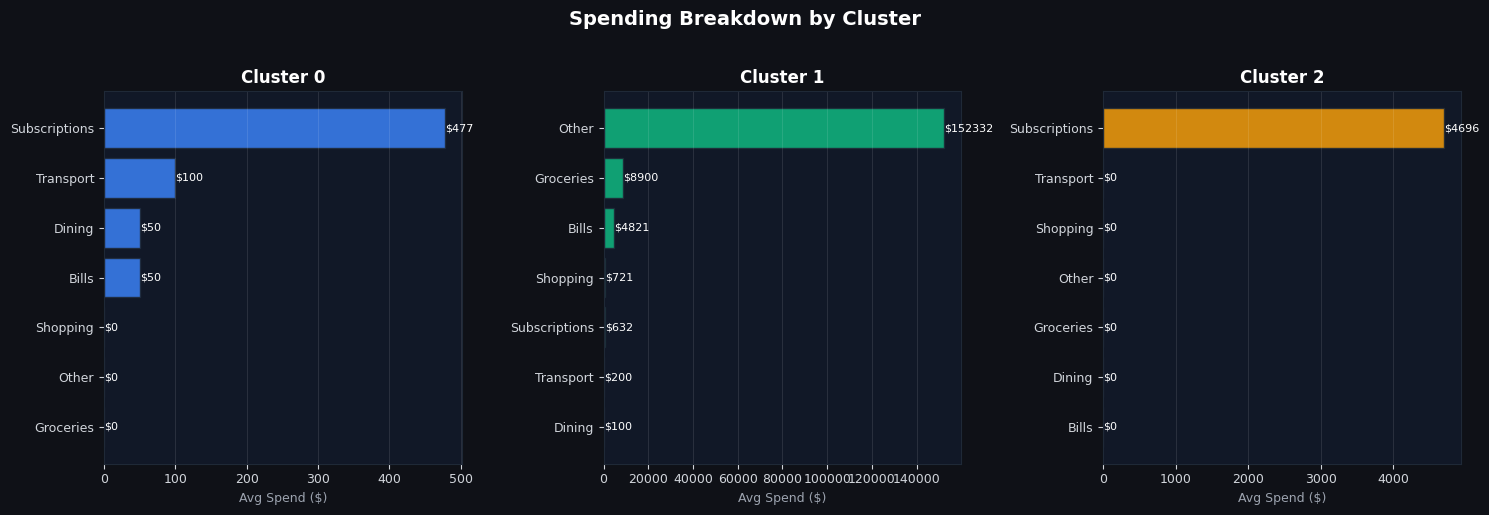

In [40]:
cat_cols = list(cat_pivot.columns)

fig, axes = plt.subplots(1, K, figsize=(15, 5), sharey=False)
fig.patch.set_facecolor(BG)
fig.suptitle("Spending Breakdown by Cluster", fontsize=14, fontweight="bold", color="white", y=1.02)

for cid, ax in enumerate(axes):
    ax.set_facecolor("#111827")
    data = cluster_profiles.loc[cid, cat_cols].sort_values(ascending=True)
    bars = ax.barh(data.index, data.values, color=COLORS[cid], alpha=0.85, edgecolor="#1f2937")
    ax.set_title(f"Cluster {cid}", color="white", fontsize=12, fontweight="bold")
    ax.tick_params(colors="#d1d5db", labelsize=9)
    ax.spines[:].set_color("#1f2937")
    ax.set_xlabel("Avg Spend ($)", color="#9ca3af", fontsize=9)
    ax.grid(axis="x", alpha=0.1, color="white")
    for bar, val in zip(bars, data.values):
        ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
                f"${val:.0f}", va="center", color="white", fontsize=8)

plt.tight_layout()
plt.show()



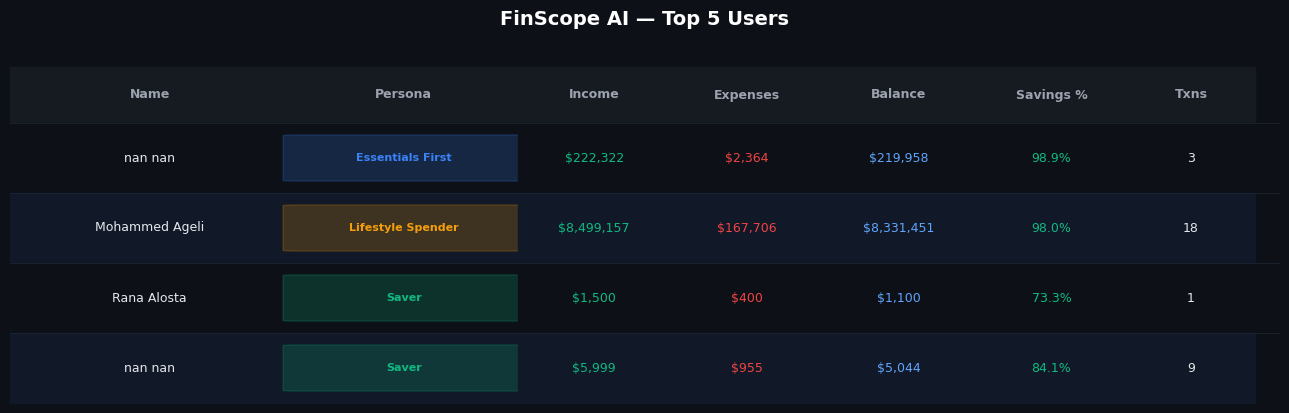

Saved: finscope_top5.png


In [46]:
from matplotlib.patches import FancyBboxPatch

BG     = "#0d1117"
HDR_BG = "#161b22"
ROW_A  = "#0d1117"
ROW_B  = "#111827"
PERSONA_COLORS = {
    "Saver":             "#10b981",
    "Lifestyle Spender": "#f59e0b",
    "Essentials First":  "#3b82f6",
}

df_5 = df_display.head(5).reset_index(drop=True)

col_labels = ["Name", "Persona", "Income", "Expenses", "Balance", "Savings %", "Txns"]
n_rows     = len(df_5)

fig, ax = plt.subplots(figsize=(13, 4))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
ax.axis("off")

fig.suptitle("FinScope AI — Top 5 Users", fontsize=14,
             fontweight="bold", color="white", y=1.02)

col_widths = [0.22, 0.18, 0.12, 0.12, 0.12, 0.12, 0.10]

# Header
x = 0
for label, cw in zip(col_labels, col_widths):
    ax.add_patch(plt.Rectangle((x, n_rows), cw, 0.8, color=HDR_BG, clip_on=False))
    ax.text(x + cw/2, n_rows + 0.4, label, ha="center", va="center",
            fontsize=9, fontweight="bold", color="#9ca3af")
    x += cw

# Rows
for i, row in df_5.iterrows():
    y  = n_rows - i - 1
    bg = ROW_A if i % 2 == 0 else ROW_B
    x  = 0
    values = [
        str(row["name"]),
        str(row["persona"]),
        "${:,.0f}".format(row["total_income"]),
        "${:,.0f}".format(row["total_expenses"]),
        "${:,.0f}".format(row["balance"]),
        "{:.1f}%".format(row["savings_rate"] * 100),
        str(int(row["txn_count"])),
    ]

    for j, (val, cw) in enumerate(zip(values, col_widths)):
        ax.add_patch(plt.Rectangle((x, y), cw, 1, color=bg, clip_on=False))

        if j == 1:
            pc = PERSONA_COLORS.get(val, "#6b7280")
            ax.add_patch(FancyBboxPatch(
                (x + 0.005, y + 0.18), cw - 0.01, 0.64,
                boxstyle="round,pad=0.01", color=pc + "33", clip_on=False))
            ax.text(x + cw/2, y + 0.5, val, ha="center", va="center",
                    fontsize=8, fontweight="bold", color=pc)
        else:
            fc = "#e5e7eb"
            if j == 2: fc = "#10b981"
            if j == 3: fc = "#ef4444"
            if j == 4: fc = "#60a5fa"
            if j == 5:
                pct = row["savings_rate"] * 100
                fc  = "#10b981" if pct >= 20 else "#f59e0b" if pct >= 10 else "#ef4444"
            ax.text(x + cw/2, y + 0.5, val, ha="center", va="center",
                    fontsize=9, color=fc)
        x += cw

# Dividers
for i in range(n_rows + 1):
    ax.axhline(n_rows - i, color="#1f2937", linewidth=0.5)

ax.set_xlim(0, 1)
ax.set_ylim(0, n_rows + 0.8)
plt.tight_layout()
plt.savefig("finscope_top5.png", dpi=180, bbox_inches="tight",
            facecolor=BG, edgecolor="none")
plt.show()
print("Saved: finscope_top5.png")

# git commit -m "feat(ml): compact top-5 user spending table with persona clustering"